In [248]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from urllib.request import urlretrieve

urlretrieve(
    "https://raw.githubusercontent.com/alexeygrigorev/datasets/master/car_fuel_efficiency.csv",
    "car_fuel_efficiency.csv",
)

('car_fuel_efficiency.csv', <http.client.HTTPMessage at 0x116c46d50>)

### Preparing the dataset 

Use only the following columns:

* `'engine_displacement'`,
* `'horsepower'`,
* `'vehicle_weight'`,
* `'model_year'`,
* `'fuel_efficiency_mpg'`

In [249]:
columns = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg',
]

df = pd.read_csv('car_fuel_efficiency.csv', usecols=columns)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9704 entries, 0 to 9703
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   engine_displacement  9704 non-null   int64  
 1   horsepower           8996 non-null   float64
 2   vehicle_weight       9704 non-null   float64
 3   model_year           9704 non-null   int64  
 4   fuel_efficiency_mpg  9704 non-null   float64
dtypes: float64(3), int64(2)
memory usage: 379.2 KB


### EDA

* Look at the `fuel_efficiency_mpg` variable. Does it have a long tail? 



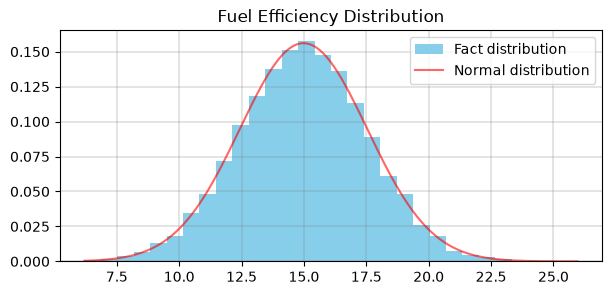

In [250]:
data = df['fuel_efficiency_mpg']

# Base chart drawing
fig, ax = plt.subplots(figsize=(7,3))
ax.hist(data, bins=30, density=True, color='skyblue', label='Fact distribution')

# Normal dist overlay
mu = data.mean()
sigma = data.std()
x = np.linspace(data.min(), data.max(), 500)
y = (
    1 / (sigma * np.sqrt(2 * np.pi))
    * np.exp(-1/2 * ((x - mu) / sigma) ** 2)
)
ax.plot(x, y, color='red', alpha=0.6, label='Normal distribution')

# Displaying parameters
ax.grid(color='gray', linewidth=0.3)
ax.set_title('Fuel Efficiency Distribution')

plt.legend()
plt.show()

### Question 1

There's one column with missing values. What is it?

* `'engine_displacement'`
* `'horsepower'`
* `'vehicle_weight'`
* `'model_year'`




In [251]:
df.isna().any(axis=0)

engine_displacement    False
horsepower              True
vehicle_weight         False
model_year             False
fuel_efficiency_mpg    False
dtype: bool

### Question 2

What's the median (50% percentile) for variable `'horsepower'`?

- 49
- 99
- 149
- 199



In [252]:
df['horsepower'].quantile(0.5)

np.float64(149.0)

### Prepare and split the dataset

* Shuffle the dataset (the filtered one you created above), use seed `42`.
* Split your data in train/val/test sets, with 60%/20%/20% distribution.

Use the same code as in the lectures




In [253]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

idx = np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
df_test = df.iloc[idx[n_train+n_val:]].reset_index(drop=True)

print(
    f'df.shape: {str(df.shape)}',
    f'df_train.shape: {str(df_train.shape)}',
    f'df_val.shape: {str(df_val.shape)}',
    f'df_test.shape: {str(df_test.shape)}',
    sep='\n'
)

df.shape: (9704, 5)
df_train.shape: (5824, 5)
df_val.shape: (1940, 5)
df_test.shape: (1940, 5)


### Question 3

* We need to deal with missing values for the column from Q1.
* We have two options: fill it with 0 or with the mean of this variable.
* Try both options. For each, train a linear regression model without regularization using the code from the lessons.
* For computing the mean, use the training only!
* Use the validation dataset to evaluate the models and compare the RMSE of each option.
* Round the RMSE scores to 2 decimal digits using `round(score, 2)`
* Which option gives better RMSE?

Options:

- With 0
- With mean
- Both are equally good




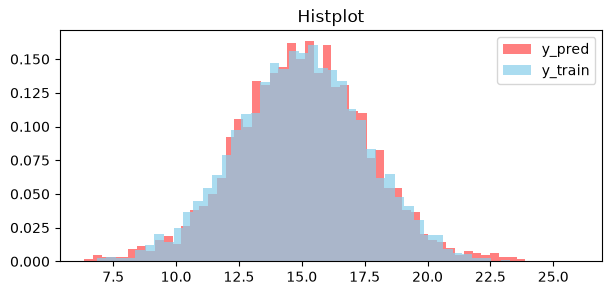

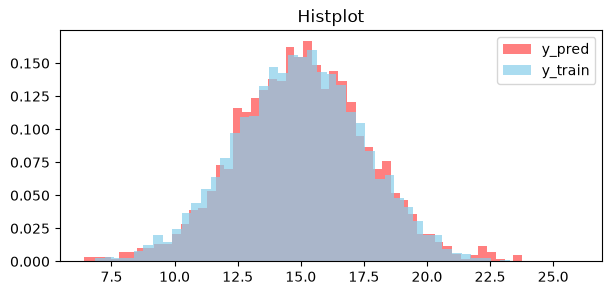

In [254]:
def train_linear_regression(X, y, reg=0):
    X = np.column_stack([np.ones(len(X)), X])
    w = np.linalg.inv(X.T @ X + np.eye(X.shape[1]) * reg).dot(X.T.dot(y))
    return w[0], w[1:]

def RMSE(y, y_pred):
    return np.sqrt(np.mean((y - y_pred) ** 2))

features = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']
horsepower_mean = df_train['horsepower'].mean()

fill_strategies = [('zero', 0), ('mean', horsepower_mean)]

results = []
for strategy, fill_value in fill_strategies:
    X_train = df_train[features].fillna({'horsepower': fill_value}).to_numpy()
    y_train = df_train['fuel_efficiency_mpg'].to_numpy()
    X_val = df_val[features].fillna({'horsepower': fill_value})
    y_val = df_val['fuel_efficiency_mpg'].to_numpy()

    bias, weights = train_linear_regression(X_train, y_train)
    # тут я сначала подумал, что нужно сделать weights[:, None]
    # но тогда пришлось бы менять и обработку вектора в RMSE()
    y_pred = bias + X_val @ weights

    rmse_value = RMSE(y_val, y_pred)
    results.append({
        'fill_strategy': strategy,
        'fill_value': np.round(fill_value, 2),
        'RMSE': np.round(rmse_value, 2)
    })

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.hist(y_pred, color='red', alpha=0.5, bins=50, label='y_pred', density=True)
    ax.hist(y_train, color='skyblue', alpha=0.7, bins=50, label='y_train', density=True)
    ax.set_title('Histplot')

    ax.legend()
    plt.show()

    plt.close()

In [255]:
val_results = pd.DataFrame(results)
display(val_results)

min_rmse_val = val_results['RMSE'].min()
best_strategy = val_results[val_results['RMSE'] == min_rmse_val]['fill_strategy'].values[0]
print(f"\nBest strategy here is to fill by {best_strategy.upper()}")

,fill_strategy,fill_value,RMSE
0,zero,0.00,0.52
1,mean,149.54,0.46



Best strategy here is to fill by MEAN


### Question 4

* Now let's train a regularized linear regression.
* For this question, fill the NAs with 0. 
* Try different values of `r` from this list: `[0, 0.01, 0.1, 1, 5, 10, 100]`.
* Use RMSE to evaluate the model on the validation dataset.
* Round the RMSE scores to 2 decimal digits.
* Which `r` gives the best RMSE?

If multiple options give the same best RMSE, select the smallest `r`.

Options:

- 0
- 0.01
- 1
- 10
- 100




In [256]:
X_train = df_train[features].fillna({'horsepower': 0}).to_numpy()
y_train = df_train['fuel_efficiency_mpg'].to_numpy()

X_val = df_val[features].fillna({'horsepower': 0}).to_numpy()
y_val = df_val['fuel_efficiency_mpg'].to_numpy()

result = []

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    bias, weights = train_linear_regression(X_train, y_train, reg=r)
    y_pred = bias + X_val @ weights 
    rmse_value = RMSE(y_val, y_pred)

    result.append({
        'reg_coef': r,
        'RMSE': np.round(rmse_value, 4)
    })

pd.DataFrame(result)

,reg_coef,RMSE
0,0.00,0.5174
1,0.01,0.5171
2,0.10,0.5188
3,1.00,0.5222
4,5.00,0.5229
5,10.00,0.5230
6,100.00,0.5231


Лучший коэффициент регуляризации: 0.01

Обучим на нем модель и проверим RMSE на тестовой выборке

In [257]:
X_train = df_train[features].fillna({'horsepower': 0}).to_numpy()
y_train = df_train['fuel_efficiency_mpg'].to_numpy()

X_test= df_test[features].fillna({'horsepower': 0}).to_numpy()
y_test = df_test['fuel_efficiency_mpg'].to_numpy()

w0, weights = train_linear_regression(X_train, y_train, 0.01)
y_pred = w0 + X_test @ weights

print(f"RMSE on test: {RMSE(y_test, y_pred):.4f}")

RMSE on test: 0.5166
